# Detecting explosive episodes with right-tailed tests

SADF changes only the endpoint, BSADF changes the start for one endpoint, and GSADF keeps the largest value over both choices:

$$
\begin{gathered}
\operatorname{SADF}(r_0)
&=\sup_{r_2\in[r_0,1]}\operatorname{ADF}_{0}^{r_2},\\
\operatorname{BSADF}_{r_2}(r_0)
&=\sup_{r_1\in[0,r_2-r_0]}\operatorname{ADF}_{r_1}^{r_2},\\
\operatorname{GSADF}(r_0)
&=\sup_{r_2\in[r_0,1]}\operatorname{BSADF}_{r_2}(r_0).
\end{gathered}
$$

Here, $r_0$ is the minimum window fraction; $r_1$ and $r_2$ are the start and end fractions of a window. $\operatorname{ADF}_{r_1}^{r_2}$ is the right-tailed statistic on that window; $\sup$ selects the largest admissible value. $\operatorname{SADF}$ is origin anchored; $\operatorname{BSADF}_{r_2}$ is endpoint specific; $\operatorname{GSADF}$ is the full-sample maximum.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
from RiskLabAI.features.structural_breaks import compute_beta, get_bsadf_sequence, get_bubble_episodes, get_expanding_window_adf, get_gsadf_statistic, get_sadf_sequence, pelt_change_points, prepare_data, psy_minimum_window, simulate_psy_critical_values, volatility_robust_sadf
DATA_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=NASDAQCOM&cosd=1994-01-01&coed=2025-12-31'
DATA_DIR = ROOT / 'data' / 'public' / 'fred'
DATA_PATH = ensure_dataset(ROOT, 'fred_nasdaq')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
raw = pd.read_csv(DATA_PATH, parse_dates=['observation_date'])
raw['NASDAQCOM'] = pd.to_numeric(raw['NASDAQCOM'], errors='coerce')
daily_price = raw.set_index('observation_date')['NASDAQCOM'].dropna().sort_index()
monthly_price = daily_price.resample('ME').last().dropna()
log_price = np.log(monthly_price).rename('log_price')
monthly_return = log_price.diff().dropna().rename('log_return')
FIGURES = ROOT / 'outputs' / 'figures' / '12_structural_breaks'
TABLES = ROOT / 'outputs' / 'tables' / '12_structural_breaks'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})
warnings.filterwarnings('ignore', message='New behaviour in v1.1.5.*')

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Public Recursive Statistics

A candidate episode begins when the endpoint statistic crosses above its critical value and ends at the first later crossing below it:

$$
\widehat r_e
=\inf\!\left\{r_2:\operatorname{BSADF}_{r_2}(r_0)>c_{r_2}\right\},
\qquad
\widehat r_f
=\inf\!\left\{r_2>\widehat r_e:\operatorname{BSADF}_{r_2}(r_0)<c_{r_2}\right\}.
$$

Here, $\widehat r_e$ and $\widehat r_f$ are estimated start and finish fractions; $r_2$ is a candidate endpoint. $\operatorname{BSADF}_{r_2}(r_0)$ is the backward supremum statistic; $c_{r_2}$ is its endpoint-specific critical value. $\inf$ selects the first qualifying endpoint; $r_0$ is the minimum window fraction.

,Method,Observed statistic,Simulated 95 percent critical value,Global rejection,Volatility-adjusted p-value,Volatility-adjusted rejection
0,SADF,1.817969,1.599310,True,0.21,False
1,GSADF,1.817969,2.311579,False,0.49,False


,Quantity,Value
0,Sample length,384
1,Minimum window,39
2,Null paths,499
3,Quantile,0.95
4,Minimum episode length,6 months
5,SADF critical value,1.599310
6,GSADF critical value,2.311579


,Candidate,First month above,First later month below,Calendar months,Global GSADF rejection
0,1,1997-05-31,1998-08-31,15,False
1,2,1999-10-31,2000-05-31,7,False
2,3,2020-07-31,2022-04-30,21,False
3,4,2025-06-30,2025-12-31,6,False


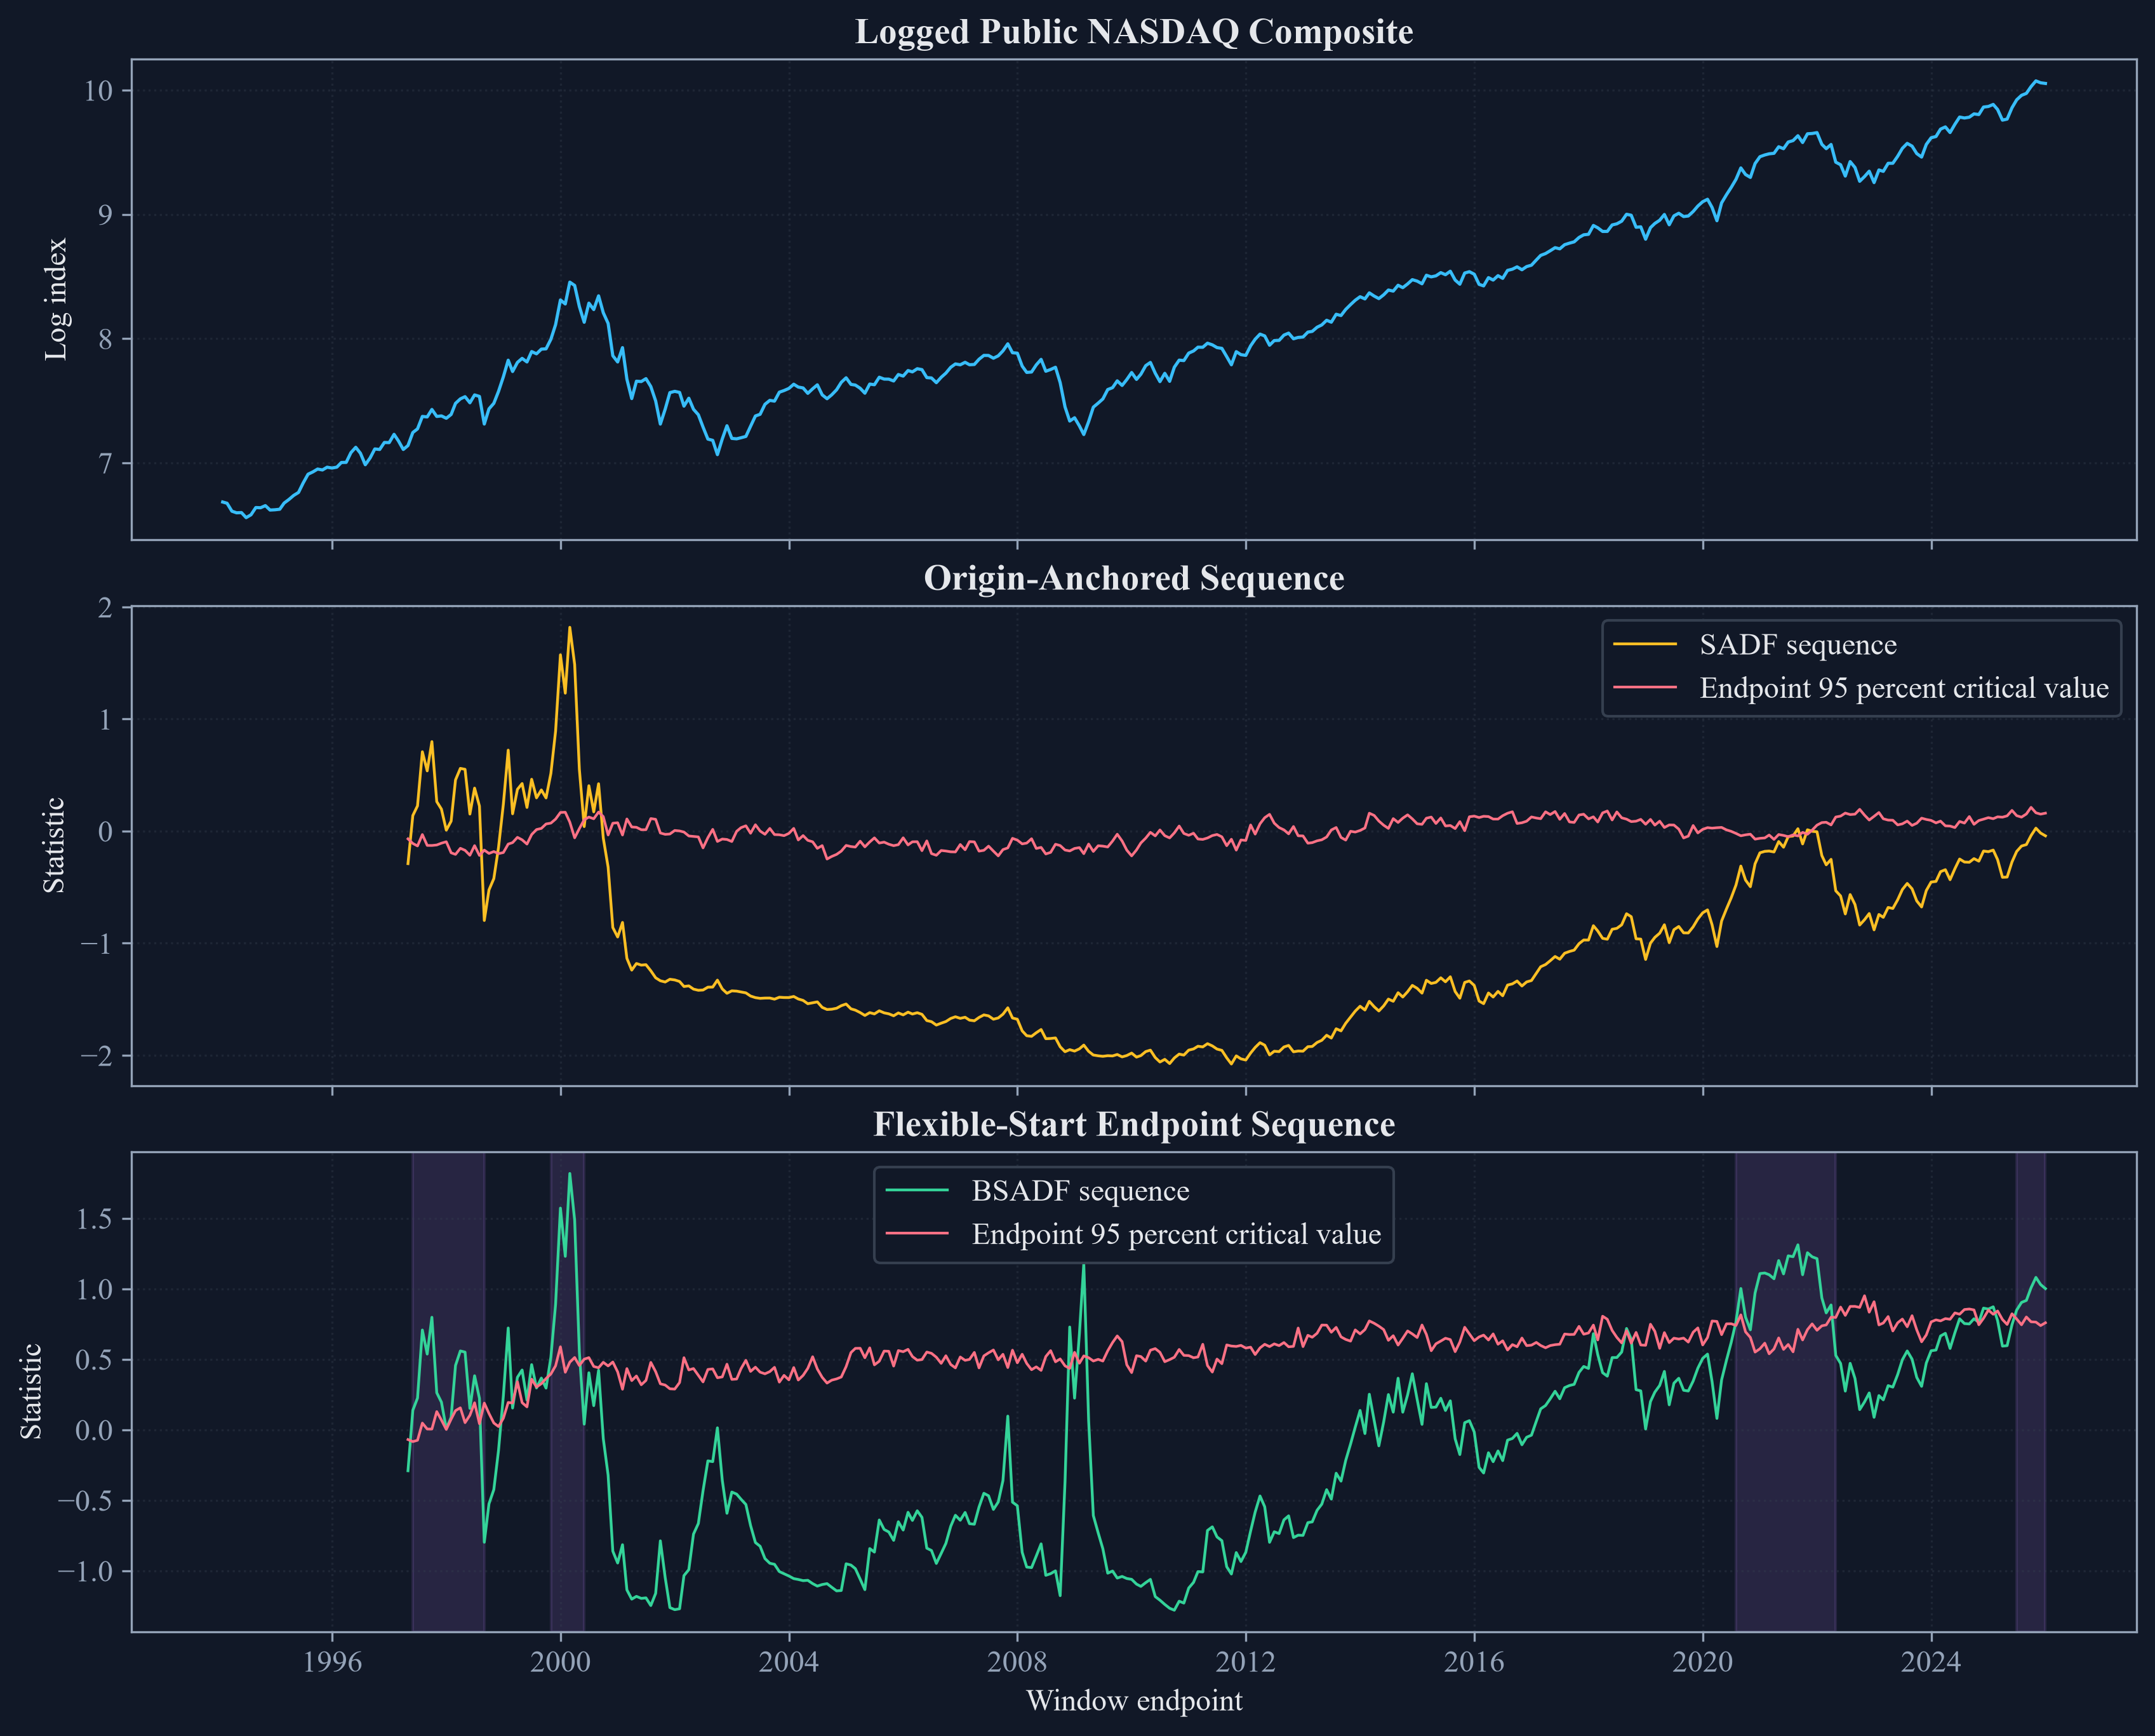

In [2]:
sample_length = len(log_price)
min_window = psy_minimum_window(sample_length)
min_duration = int(round(np.log(sample_length)))
sadf_sequence = get_sadf_sequence(log_price, min_window)
bsadf_sequence = get_bsadf_sequence(log_price, min_window)
critical = simulate_psy_critical_values(sample_length, min_window, n_simulations=499, level=0.95, seed=2718)
sadf_critical_sequence = pd.Series(critical["sadf_sequence_cv"], index=sadf_sequence.index)
bsadf_critical_sequence = pd.Series(critical["bsadf_sequence_cv"], index=bsadf_sequence.index)
sadf_statistic = float(sadf_sequence.max())
gsadf_statistic = get_gsadf_statistic(log_price, min_window)
public_episodes = get_bubble_episodes(bsadf_sequence, bsadf_critical_sequence, min_duration=min_duration)
robust_public = volatility_robust_sadf(log_price, min_length=min_window, n_bootstrap=399, random_state=20260927)

recursive_public_summary = pd.DataFrame({
    "Method": ["SADF", "GSADF"],
    "Observed statistic": [sadf_statistic, gsadf_statistic],
    "Simulated 95 percent critical value": [critical["sadf_global_cv"], critical["gsadf_global_cv"]],
    "Global rejection": [sadf_statistic > critical["sadf_global_cv"], gsadf_statistic > critical["gsadf_global_cv"]],
    "Volatility-adjusted p-value": [robust_public["sadf_pvalue"], robust_public["gsadf_pvalue"]],
    "Volatility-adjusted rejection": [robust_public["reject_sadf"], robust_public["reject_gsadf"]],
})
save_table(recursive_public_summary, "recursive_public_summary", "Recursive right-tailed tests on the fixed public NASDAQ sample.", "tab:chapter11-recursive-public-summary", fit=True)
display(recursive_public_summary.round(6))

critical_value_summary = pd.DataFrame({
    "Quantity": ["Sample length", "Minimum window", "Null paths", "Quantile", "Minimum episode length", "SADF critical value", "GSADF critical value"],
    "Value": [f"{sample_length}", f"{min_window}", "499", "0.95", f"{min_duration} months", f"{critical['sadf_global_cv']:.6f}", f"{critical['gsadf_global_cv']:.6f}"],
})
save_table(critical_value_summary, "critical_value_summary", "Finite-sample random-walk calibration used for the public recursive tests.", "tab:chapter11-critical-value-summary", fit=False)
display(critical_value_summary)

public_candidate_episodes = pd.DataFrame([
    {"Candidate": number + 1, "First month above": str(start.date()), "First later month below": str(finish.date()), "Calendar months": (finish.to_period("M") - start.to_period("M")).n, "Global GSADF rejection": gsadf_statistic > critical["gsadf_global_cv"]}
    for number, (start, finish) in enumerate(public_episodes)
])
save_table(public_candidate_episodes, "public_candidate_episodes", "Endpoint threshold crossings in the public BSADF sequence. The global GSADF test is reported separately.", "tab:chapter11-public-candidate-episodes", fit=True)
display(public_candidate_episodes)

figure, axes = plt.subplots(3, 1, figsize=(11.2, 9.0), sharex=True, constrained_layout=True)
axes[0].plot(log_price.index, log_price, color=palette["cyan"], linewidth=1.2)
axes[0].set_title("Logged Public NASDAQ Composite")
axes[0].set_ylabel("Log index")
axes[0].grid(alpha=0.35)
axes[1].plot(sadf_sequence.index, sadf_sequence, color=palette["amber"], linewidth=1.05, label="SADF sequence")
axes[1].plot(sadf_critical_sequence.index, sadf_critical_sequence, color=palette["rose"], linewidth=1.0, label="Endpoint 95 percent critical value")
axes[1].set_title("Origin-Anchored Sequence")
axes[1].set_ylabel("Statistic")
axes[1].legend()
axes[1].grid(alpha=0.35)
axes[2].plot(bsadf_sequence.index, bsadf_sequence, color=palette["green"], linewidth=1.05, label="BSADF sequence")
axes[2].plot(bsadf_critical_sequence.index, bsadf_critical_sequence, color=palette["rose"], linewidth=1.0, label="Endpoint 95 percent critical value")
for start, finish in public_episodes:
    axes[2].axvspan(start, finish, color=palette["violet"], alpha=0.13)
axes[2].set_title("Flexible-Start Endpoint Sequence")
axes[2].set_xlabel("Window endpoint")
axes[2].set_ylabel("Statistic")
axes[2].legend()
axes[2].grid(alpha=0.35)
locator = mdates.AutoDateLocator(minticks=6, maxticks=10)
axes[2].xaxis.set_major_locator(locator)
axes[2].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
figure.savefig(FIGURES / "recursive_statistics_public.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "recursive_statistics_public.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "recursive_statistics_public.png")))
plt.close(figure)

## A Controlled Two-Episode Path

The controlled path alternates between random-walk periods, two mildly explosive intervals, and an explicit reset after each interval:

$$
y_t=
\begin{cases}
\rho y_{t-1}+\varepsilon_t,&a_j\leq t<b_j,\\
y_{a_j-1}+\varepsilon_t,&t=b_j,\\
y_{t-1}+\varepsilon_t,&\text{otherwise},
\end{cases}
\qquad
\rho=1.055,
\qquad
\varepsilon_t\sim\mathcal N(0,1).
$$

Here, $y_t$ is the controlled level; $t$ is the observation number; $(a_j,b_j)$ is explosive interval $j.$ $\rho=1.055$ is the explosive coefficient; $\varepsilon_t$ is an independent standard-normal shock; $\mathcal N(0,1)$ is its distribution. $y_{a_j-1}$ is the level immediately before episode $j$ and supplies the reset level at $b_j.$

,Method,Global statistic,Global 95 percent critical value,Detected episodes,True starts matched within 20,Mean nearest-start error,Detected intervals
0,SADF,5.660012,1.494356,1,1,60,"[(93, 115)]"
1,BSADF and GSADF,7.236070,2.312003,2,2,12,"[(90, 115), (214, 235)]"


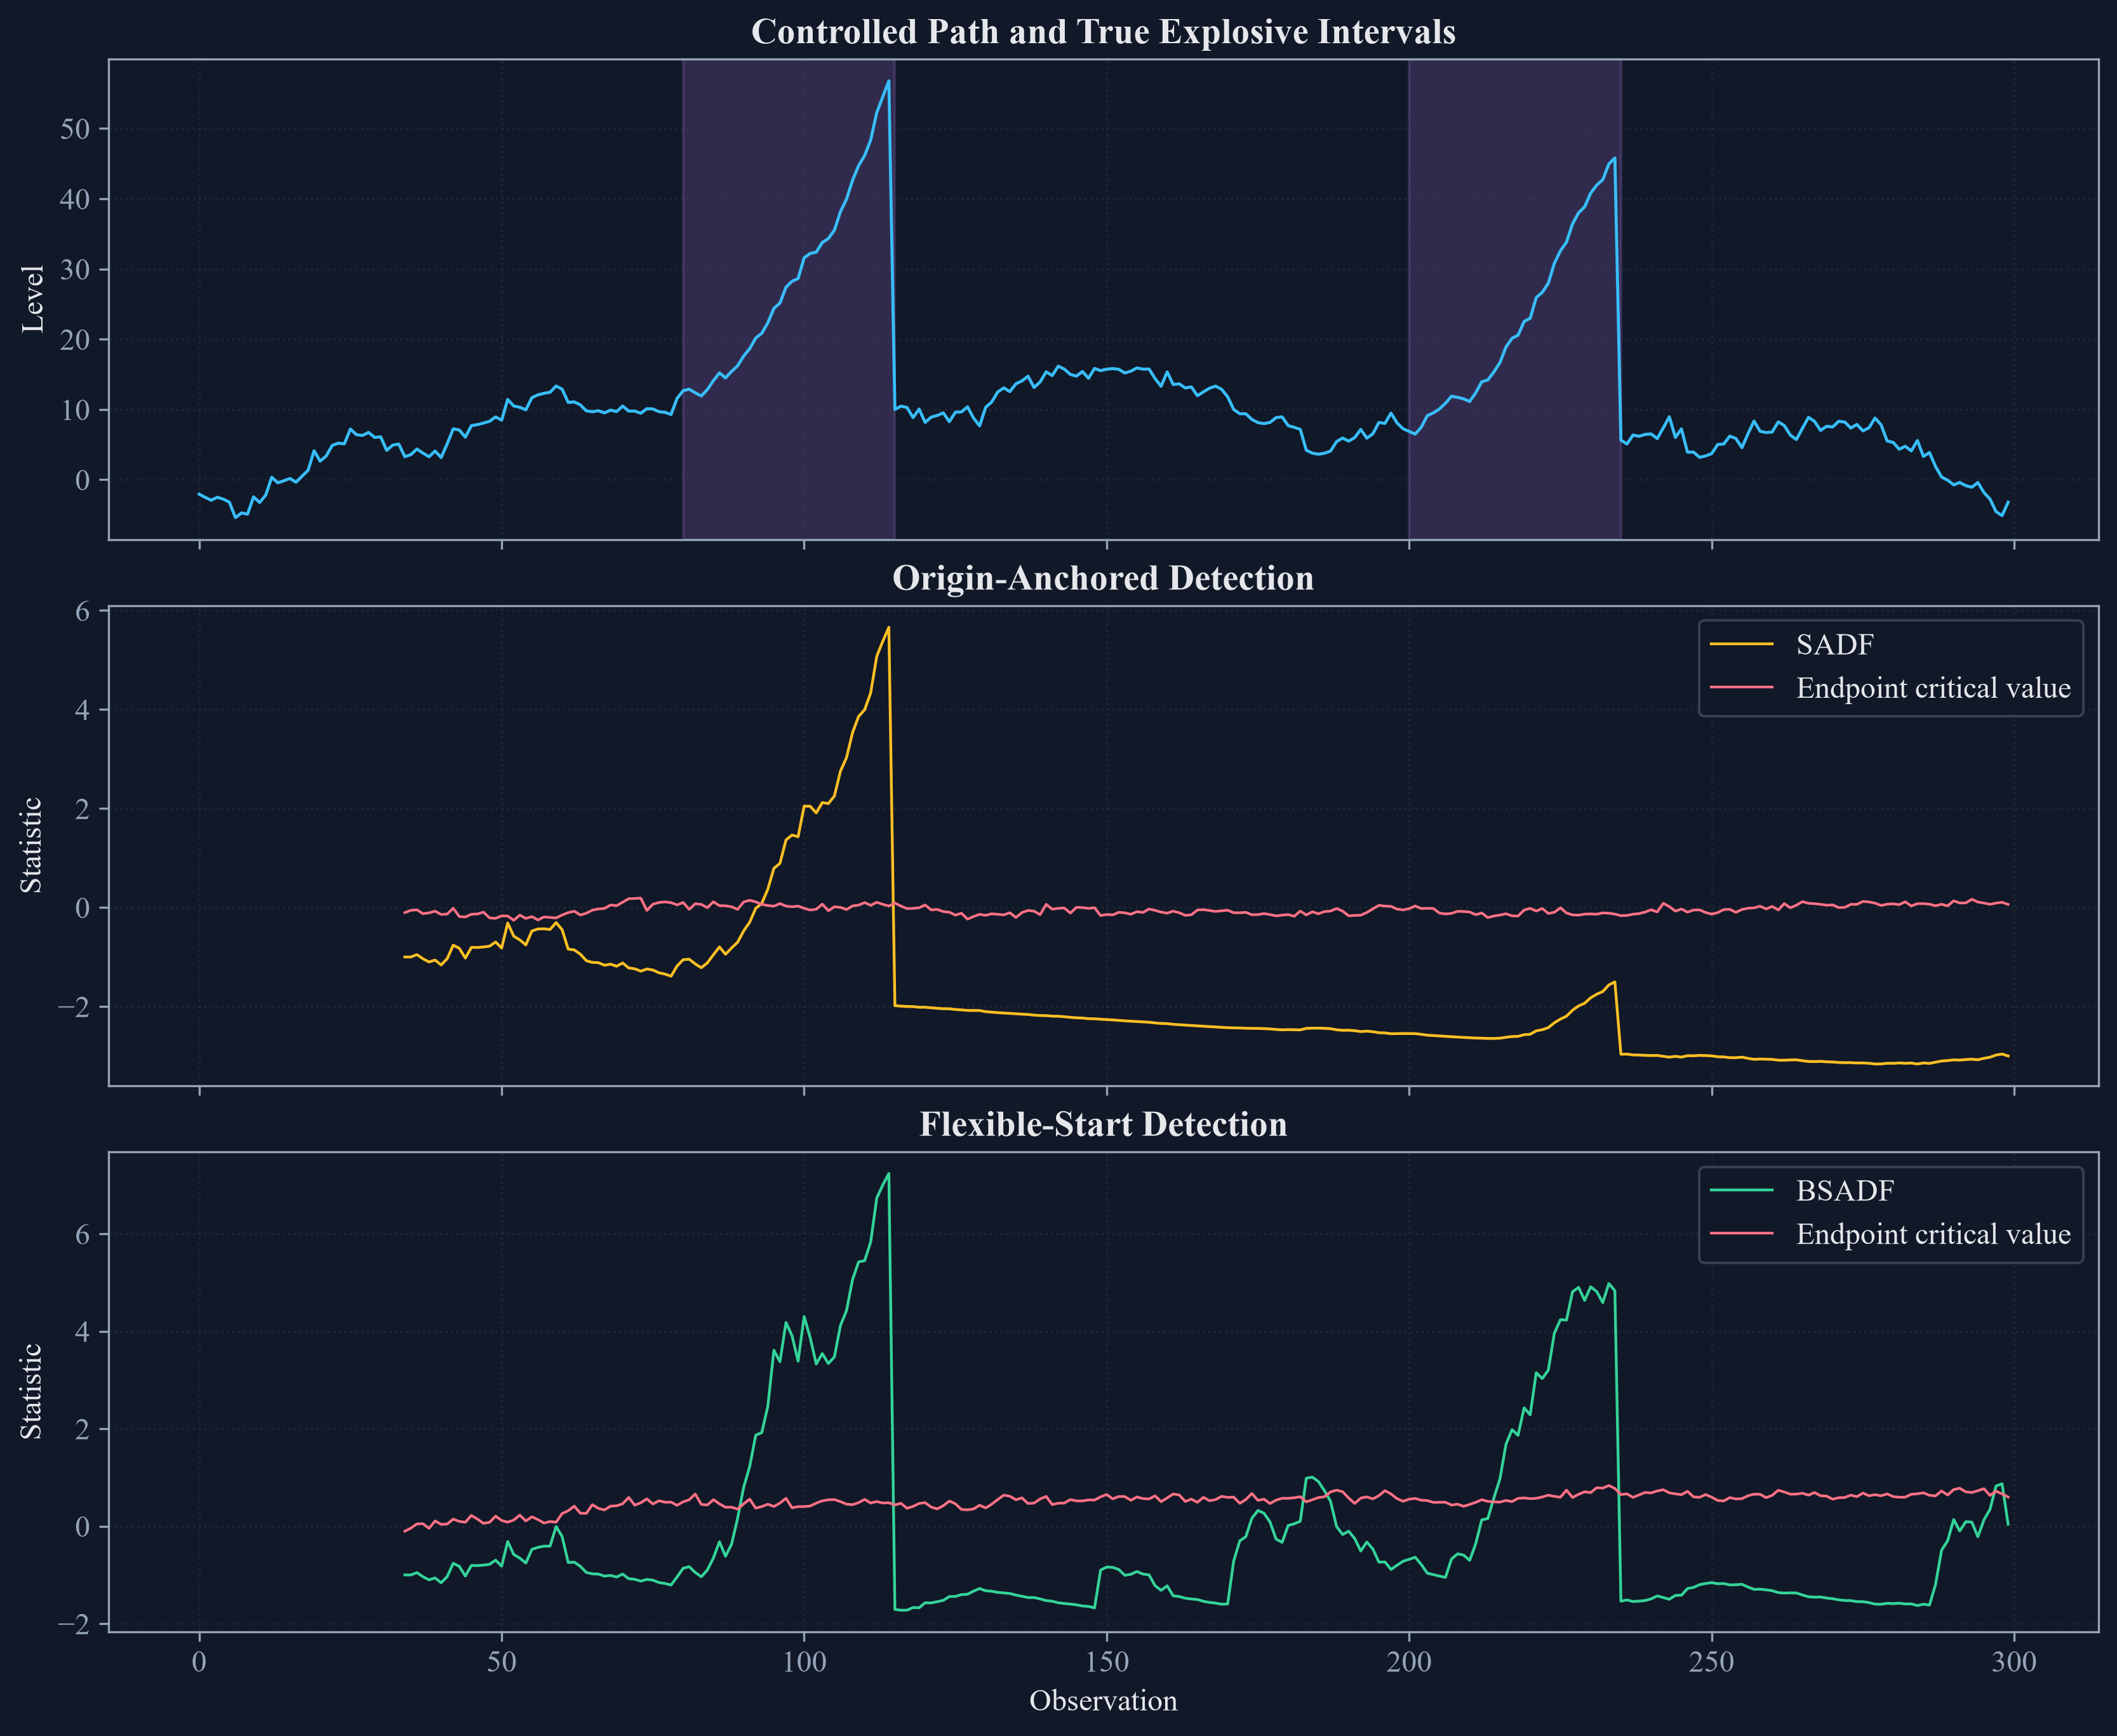

In [3]:
controlled_length = 300
true_intervals = [(80, 115), (200, 235)]
controlled_rng = np.random.default_rng(20260927)
controlled_shocks = controlled_rng.standard_normal(controlled_length)
controlled_path = np.empty(controlled_length)
controlled_path[0] = controlled_shocks[0]
for time in range(1, controlled_length):
    active = next(((start, finish) for start, finish in true_intervals if start <= time < finish), None)
    ending = next(((start, finish) for start, finish in true_intervals if time == finish), None)
    if active is not None:
        controlled_path[time] = 1.055 * controlled_path[time - 1] + controlled_shocks[time]
    elif ending is not None:
        controlled_path[time] = controlled_path[ending[0] - 1] + controlled_shocks[time]
    else:
        controlled_path[time] = controlled_path[time - 1] + controlled_shocks[time]
controlled_series = pd.Series(controlled_path, index=pd.RangeIndex(controlled_length), name="level")
controlled_min_window = psy_minimum_window(controlled_length)
controlled_critical = simulate_psy_critical_values(controlled_length, controlled_min_window, n_simulations=399, level=0.95, seed=2718)
controlled_sadf = get_sadf_sequence(controlled_series, controlled_min_window)
controlled_bsadf = get_bsadf_sequence(controlled_series, controlled_min_window)
controlled_sadf_cv = pd.Series(controlled_critical["sadf_sequence_cv"], index=controlled_sadf.index)
controlled_bsadf_cv = pd.Series(controlled_critical["bsadf_sequence_cv"], index=controlled_bsadf.index)
controlled_duration = int(round(np.log(controlled_length)))
sadf_episodes = get_bubble_episodes(controlled_sadf, controlled_sadf_cv, min_duration=controlled_duration)
bsadf_episodes = get_bubble_episodes(controlled_bsadf, controlled_bsadf_cv, min_duration=controlled_duration)

def matched_starts(episodes, tolerance=20):
    starts = [start for start, finish in episodes]
    errors = [min((abs(value - truth) for value in starts), default=np.inf) for truth, finish in true_intervals]
    matched = sum(error <= tolerance for error in errors)
    finite_errors = [error for error in errors if np.isfinite(error)]
    return matched, float(np.mean(finite_errors)) if finite_errors else np.nan

sadf_matched, sadf_start_error = matched_starts(sadf_episodes)
bsadf_matched, bsadf_start_error = matched_starts(bsadf_episodes)
two_bubble_detection = pd.DataFrame({
    "Method": ["SADF", "BSADF and GSADF"],
    "Global statistic": [controlled_sadf.max(), controlled_bsadf.max()],
    "Global 95 percent critical value": [controlled_critical["sadf_global_cv"], controlled_critical["gsadf_global_cv"]],
    "Detected episodes": [len(sadf_episodes), len(bsadf_episodes)],
    "True starts matched within 20": [sadf_matched, bsadf_matched],
    "Mean nearest-start error": [sadf_start_error, bsadf_start_error],
    "Detected intervals": [str(sadf_episodes), str(bsadf_episodes)],
})
save_table(two_bubble_detection, "two_bubble_detection", "Known-truth comparison on a path with two explosive intervals.", "tab:chapter11-two-bubble-detection", fit=True)
display(two_bubble_detection.round(6))

figure, axes = plt.subplots(3, 1, figsize=(11.0, 9.0), sharex=True, constrained_layout=True)
axes[0].plot(controlled_series.index, controlled_series, color=palette["cyan"], linewidth=1.15)
for start, finish in true_intervals:
    axes[0].axvspan(start, finish, color=palette["violet"], alpha=0.18)
axes[0].set_title("Controlled Path and True Explosive Intervals")
axes[0].set_ylabel("Level")
axes[0].grid(alpha=0.35)
axes[1].plot(controlled_sadf.index, controlled_sadf, color=palette["amber"], linewidth=1.05, label="SADF")
axes[1].plot(controlled_sadf_cv.index, controlled_sadf_cv, color=palette["rose"], linewidth=1.0, label="Endpoint critical value")
axes[1].set_title("Origin-Anchored Detection")
axes[1].set_ylabel("Statistic")
axes[1].legend()
axes[1].grid(alpha=0.35)
axes[2].plot(controlled_bsadf.index, controlled_bsadf, color=palette["green"], linewidth=1.05, label="BSADF")
axes[2].plot(controlled_bsadf_cv.index, controlled_bsadf_cv, color=palette["rose"], linewidth=1.0, label="Endpoint critical value")
axes[2].set_title("Flexible-Start Detection")
axes[2].set_xlabel("Observation")
axes[2].set_ylabel("Statistic")
axes[2].legend()
axes[2].grid(alpha=0.35)
figure.savefig(FIGURES / "two_bubble_detection.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "two_bubble_detection.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "two_bubble_detection.png")))
plt.close(figure)

## Volatility Adjustment

Random sign changes preserve the size pattern of observed shocks while forming a null distribution for the recursive statistic:

$$
\widetilde\varepsilon_t=\Delta y_t-\overline{\Delta y},
\qquad
y_t^{*(b)}=y_0+\sum_{j=1}^{t}\xi_j^{(b)}\widetilde\varepsilon_j,
\qquad
\xi_j^{(b)}\in\{-1,1\},
\qquad
\widehat p=\frac{1+\sum_{b=1}^{B}\mathbf 1\{S_b^*\geq S_{\mathrm{obs}}\}}{B+1}.
$$

Here, $\widetilde\varepsilon_t$ is a demeaned first difference; $\overline{\Delta y}$ is the average first difference. $b$ labels one resample; $B$ is the number of resamples; $\xi_j^{(b)}$ is an independent sign; $y_t^{*(b)}$ is a resampled path. $S_{\mathrm{obs}}$ is the observed SADF or GSADF value; $S_b^*$ is its resampled value; $\mathbf 1\{\cdot\}$ is an indicator; $\widehat p$ is the adjusted p-value.

,Scenario,Calibration,Rejections,Repetitions,Rejection rate,Simulation standard error
0,Constant volatility,Constant-volatility critical value,3,32,0.09375,0.051527
1,Constant volatility,Volatility-adjusted signs,4,32,0.12500,0.058463
2,Sixfold volatility break,Constant-volatility critical value,25,32,0.78125,0.073079
3,Sixfold volatility break,Volatility-adjusted signs,2,32,0.06250,0.042791


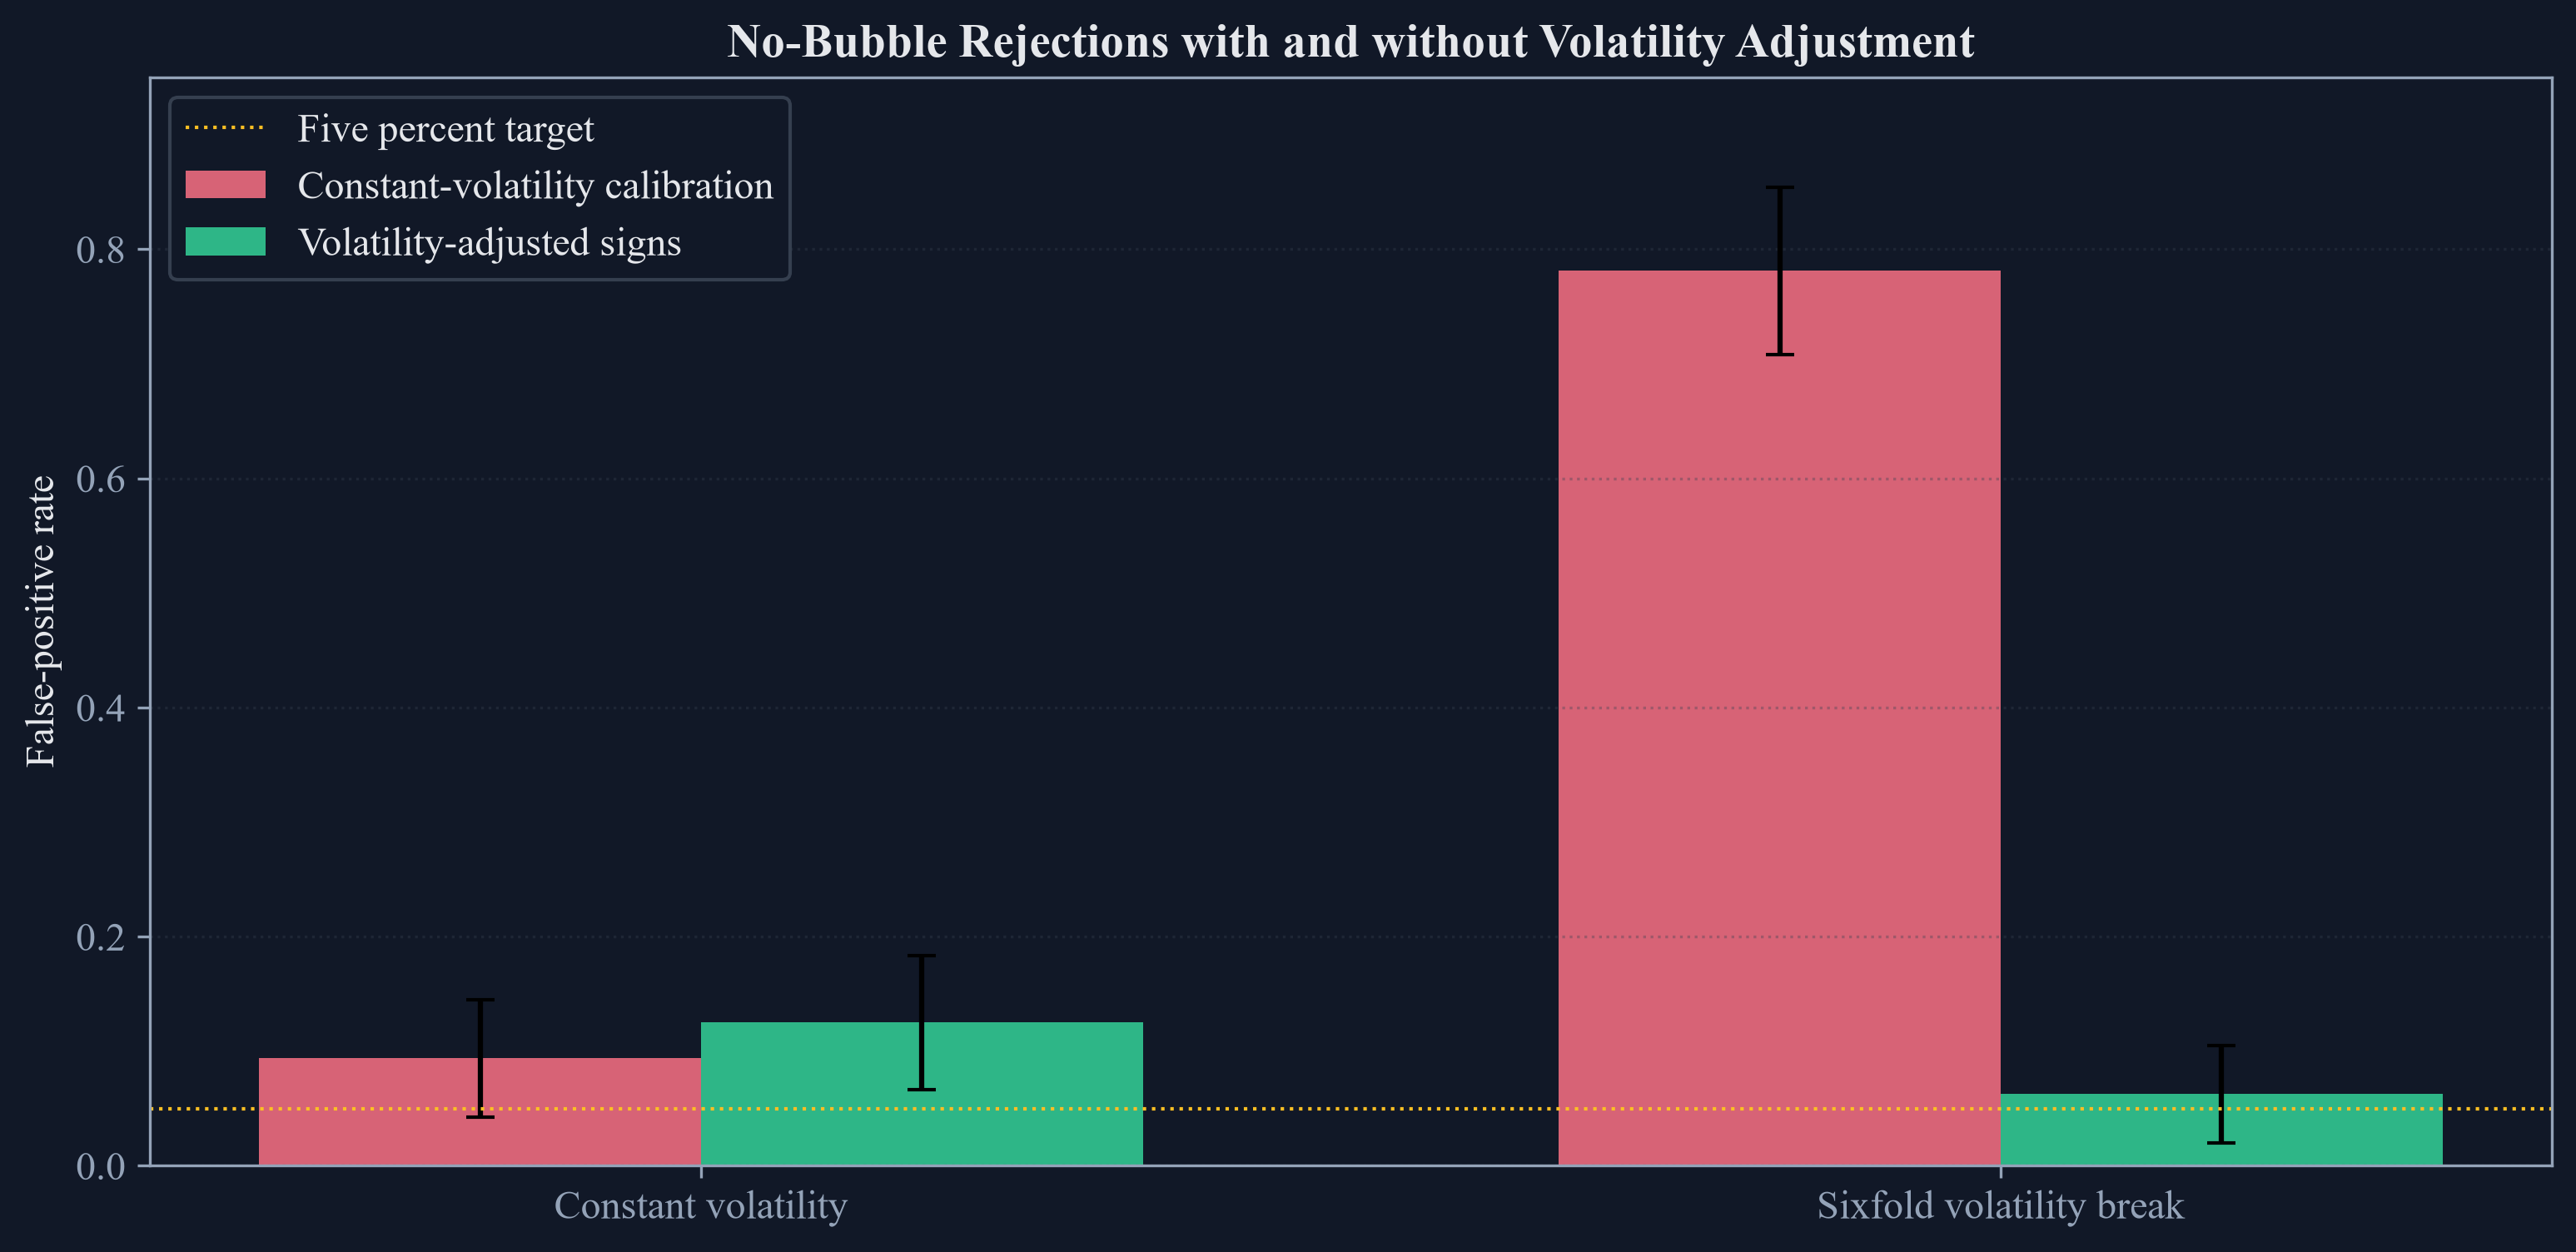

In [4]:
variance_length = 130
variance_min_window = psy_minimum_window(variance_length)
variance_repetitions = 32
bootstrap_repetitions = 79
plain_critical = simulate_psy_critical_values(variance_length, variance_min_window, n_simulations=599, level=0.95, seed=31415)["sadf_global_cv"]
variance_rows = []
for scenario, strength in [("Constant volatility", 1.0), ("Sixfold volatility break", 6.0)]:
    plain_rejections = 0
    adjusted_rejections = 0
    for repetition in range(variance_repetitions):
        variance_rng = np.random.default_rng(8000 + repetition)
        sigma = np.ones(variance_length)
        sigma[variance_length // 2 :] = strength
        variance_path = np.cumsum(variance_rng.standard_normal(variance_length) * sigma)
        adjusted = volatility_robust_sadf(variance_path, min_length=variance_min_window, n_bootstrap=bootstrap_repetitions, random_state=9000 + repetition)
        plain_rejections += adjusted["sadf"] > plain_critical
        adjusted_rejections += adjusted["sadf_pvalue"] < 0.05
    plain_rate = plain_rejections / variance_repetitions
    adjusted_rate = adjusted_rejections / variance_repetitions
    variance_rows.extend([
        {"Scenario": scenario, "Calibration": "Constant-volatility critical value", "Rejections": plain_rejections, "Repetitions": variance_repetitions, "Rejection rate": plain_rate, "Simulation standard error": np.sqrt(plain_rate * (1 - plain_rate) / variance_repetitions)},
        {"Scenario": scenario, "Calibration": "Volatility-adjusted signs", "Rejections": adjusted_rejections, "Repetitions": variance_repetitions, "Rejection rate": adjusted_rate, "Simulation standard error": np.sqrt(adjusted_rate * (1 - adjusted_rate) / variance_repetitions)},
    ])
volatility_break_size = pd.DataFrame(variance_rows)
save_table(volatility_break_size, "volatility_break_size", "False-positive rates under two no-bubble random walks. Simulation uncertainty is shown because only 32 repetitions are used.", "tab:chapter11-volatility-break-size", fit=True)
display(volatility_break_size.round(6))

figure, axis = plt.subplots(figsize=(10.2, 4.9), constrained_layout=True)
scenarios = ["Constant volatility", "Sixfold volatility break"]
locations = np.arange(len(scenarios))
width = 0.34
plain_rows = volatility_break_size.loc[volatility_break_size["Calibration"] == "Constant-volatility critical value"].set_index("Scenario").loc[scenarios]
adjusted_rows = volatility_break_size.loc[volatility_break_size["Calibration"] == "Volatility-adjusted signs"].set_index("Scenario").loc[scenarios]
axis.bar(locations - width / 2, plain_rows["Rejection rate"], width, yerr=plain_rows["Simulation standard error"], color=palette["rose"], alpha=0.85, capsize=4, label="Constant-volatility calibration")
axis.bar(locations + width / 2, adjusted_rows["Rejection rate"], width, yerr=adjusted_rows["Simulation standard error"], color=palette["green"], alpha=0.85, capsize=4, label="Volatility-adjusted signs")
axis.axhline(0.05, color=palette["amber"], linewidth=1.0, linestyle=":", label="Five percent target")
axis.set_xticks(locations, scenarios)
axis.set_ylim(0, 0.95)
axis.set_ylabel("False-positive rate")
axis.set_title("No-Bubble Rejections with and without Volatility Adjustment")
axis.legend()
axis.grid(axis="y", alpha=0.35)
figure.savefig(FIGURES / "volatility_adjustment_experiment.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "volatility_adjustment_experiment.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "volatility_adjustment_experiment.png")))
plt.close(figure)

## Tests

In [5]:
assert sample_length == 384
assert min_window == 39
assert len(sadf_sequence) == len(bsadf_sequence) == sample_length - min_window
assert sadf_sequence.index.equals(bsadf_sequence.index)
assert np.isclose(sadf_statistic, sadf_sequence.max())
assert np.isclose(gsadf_statistic, bsadf_sequence.max())
assert np.isclose(sadf_statistic, 1.8179690572971872, atol=1e-10)
assert np.isclose(gsadf_statistic, 1.8179690572971872, atol=1e-10)
assert critical['gsadf_global_cv'] > critical['sadf_global_cv']
assert recursive_public_summary['Global rejection'].tolist() == [True, False]
assert not recursive_public_summary['Volatility-adjusted rejection'].any()
assert robust_public['sadf_pvalue'] == 0.21
assert robust_public['gsadf_pvalue'] == 0.49
assert len(public_episodes) >= 3
assert public_candidate_episodes['Calendar months'].ge(min_duration).all()
assert controlled_min_window == 34
assert controlled_sadf.max() > controlled_critical['sadf_global_cv']
assert controlled_bsadf.max() > controlled_critical['gsadf_global_cv']
assert len(sadf_episodes) == 1
assert len(bsadf_episodes) == 2
assert sadf_matched == 1
assert bsadf_matched == 2
assert variance_repetitions == 32
assert bootstrap_repetitions == 79
assert volatility_break_size.shape == (4, 6)
assert volatility_break_size['Rejection rate'].between(0, 1).all()
assert plain_rows.loc['Sixfold volatility break', 'Rejection rate'] >= 0.6
assert adjusted_rows.loc['Sixfold volatility break', 'Rejection rate'] <= 0.2
assert plain_rows.loc['Sixfold volatility break', 'Rejection rate'] > adjusted_rows.loc['Sixfold volatility break', 'Rejection rate']
assert (FIGURES / 'recursive_statistics_public.pdf').is_file()
assert (FIGURES / 'two_bubble_detection.pdf').is_file()
assert (FIGURES / 'volatility_adjustment_experiment.pdf').is_file()
assert (TABLES / 'recursive_public_summary.tex').is_file()
assert (TABLES / 'critical_value_summary.tex').is_file()
assert (TABLES / 'public_candidate_episodes.tex').is_file()
assert (TABLES / 'two_bubble_detection.tex').is_file()
assert (TABLES / 'volatility_break_size.tex').is_file()
